In [8]:
import os
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
from pathlib import Path
from PIL import Image
from IPython.display import display
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')

DRIVE_ROOT = Path('/content/drive/MyDrive/DLproj')
LOCAL_DATA = Path('/content/dataset')
ZIP_PATH = DRIVE_ROOT / 'SUIM_new.zip'

if ZIP_PATH.is_file():
    print(f'Found {ZIP_PATH.name} at {DRIVE_ROOT}. Extracting to {LOCAL_DATA} for fast I/O...')
    LOCAL_DATA.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(LOCAL_DATA)
    print('Extraction complete!')
else:
    print(f'Error: Could not find {ZIP_PATH.name} in {DRIVE_ROOT}. Please verify the file exists.')

DATA_ROOT = LOCAL_DATA if LOCAL_DATA.is_dir() else DRIVE_ROOT

TRAIN_DIR = DATA_ROOT / 'SUIM_new' / 'train_val'
if not TRAIN_DIR.is_dir():
    TRAIN_DIR = DATA_ROOT / 'train_val'

TEST_DIR = DATA_ROOT / 'SUIM_new' / 'TEST'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found SUIM_new.zip at /content/drive/MyDrive/DLproj. Extracting to /content/dataset for fast I/O...
Extraction complete!
-----------------------------------------
Train Directory: /content/dataset/SUIM_new/train_val (Exists: True )
Test Directory: /content/dataset/SUIM_new/TEST (Exists: True )
-----------------------------------------


In [21]:
IMG_HEIGHT, IMG_WIDTH = 256, 256
BATCH_SIZE = 4
EPOCHS = 50
CLASSES = ['RO', 'FV', 'HD', 'RI', 'WR']
def build_mini_unet(input_shape=(128, 128, 3), num_classes=5):
    inputs = layers.Input(shape=input_shape)

    # Encoder (Downsampling)
    c1 = layers.Conv2D(16, (3, 3), activation='relu', padding='same')(inputs)
    p1 = layers.MaxPooling2D((2, 2))(c1)

    c2 = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(p1)
    p2 = layers.MaxPooling2D((2, 2))(c2)

    # Bottleneck
    c3 = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(p2)

    # Decoder (Upsampling)
    u2 = layers.Conv2DTranspose(32, (2, 2), strides=(2, 2), padding='same')(c3)
    u2 = layers.concatenate([u2, c2])
    c4 = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(u2)

    u1 = layers.Conv2DTranspose(16, (2, 2), strides=(2, 2), padding='same')(c4)
    u1 = layers.concatenate([u1, c1])
    c5 = layers.Conv2D(16, (3, 3), activation='relu', padding='same')(u1)

    outputs = layers.Conv2D(num_classes, (1, 1), activation='sigmoid')(c5)

    model = models.Model(inputs=[inputs], outputs=[outputs])
    return model

def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.reshape(tf.cast(y_true, tf.float32), [-1])
    y_pred_f = tf.reshape(tf.cast(y_pred, tf.float32), [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

model = build_mini_unet(input_shape=(IMG_HEIGHT, IMG_WIDTH, 3), num_classes=len(CLASSES))
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=[dice_coef])
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 256, 256,  │        448 │ input_layer_3[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 128, 128,  │          0 │ conv2d_18[0][0]   │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 128, 128,  │      4,640 │ max_pooling2d_6[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 64, 64,    │          0 │ conv2d_19[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 64, 64,    │     18,496 │ max_pooling2d_7[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_6  │ (None, 128, 128,  │      8,224 │ conv2d_20[0][0]   │
│ (Conv2DTranspose)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_6       │ (None, 128, 128,  │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 64)               │            │ conv2d_19[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 128, 128,  │     18,464 │ concatenate_6[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_7  │ (None, 256, 256,  │      2,064 │ conv2d_21[0][0]   │
│ (Conv2DTranspose)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_7       │ (None, 256, 256,  │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 32)               │            │ conv2d_18[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 256, 256,  │      4,624 │ concatenate_7[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 256, 256,  │         85 │ conv2d_22[0][0]   │
│                     │ 5)                │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 57,045 (222.83 KB)

 Trainable params: 57,045 (222.83 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
import glob

def load_dataset(images_dir, masks_dir, size):
    image_paths = sorted(glob.glob(str(images_dir / 'images' / '*.*')))
    xs, ys = [], []

    # Colors for SUIM 5 classes
    colors = np.array([(1, 0, 0), (1, 1, 0), (0, 0, 1), (1, 0, 1), (0, 1, 1)])

    for img_path in image_paths:
        stem = Path(img_path).stem
        mask_path = masks_dir / f'{stem}.bmp'
        if not mask_path.exists():
            mask_path = masks_dir / f'{stem}.png'
        if not mask_path.exists():
            continue

        img = Image.open(img_path).convert('RGB').resize((size[1], size[0]), Image.Resampling.BILINEAR)
        mask = Image.open(mask_path).convert('RGB').resize((size[1], size[0]), Image.Resampling.NEAREST)

        img_arr = np.asarray(img, dtype=np.float32) / 255.0
        mask_arr = np.asarray(mask, dtype=np.float32)

        target = np.all(mask_arr[..., None, :] == (colors * 255), axis=-1).astype(np.float32)

        xs.append(img_arr)
        ys.append(target)

    return np.array(xs), np.array(ys)

print("Loading training data into memory...")
X_train, Y_train = load_dataset(TRAIN_DIR, TRAIN_DIR / 'masks', (IMG_HEIGHT, IMG_WIDTH))
print(f"Loaded {len(X_train)} training samples.")

history = model.fit(X_train, Y_train, batch_size=BATCH_SIZE, epochs=EPOCHS, validation_split=0.2, shuffle=True)

Loading training data into memory...
Loaded 1525 training samples.
Epoch 1/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 15s 33ms/step - dice_coef: 0.3413 - loss: 0.2519 - val_dice_coef: 0.1236 - val_loss: 0.4977
Epoch 2/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - dice_coef: 0.4039 - loss: 0.2055 - val_dice_coef: 0.1335 - val_loss: 0.5456
Epoch 3/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - dice_coef: 0.4125 - loss: 0.2032 - val_dice_coef: 0.1120 - val_loss: 0.4324
Epoch 4/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - dice_coef: 0.4156 - loss: 0.2016 - val_dice_coef: 0.1209 - val_loss: 0.4678
Epoch 5/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - dice_coef: 0.4173 - loss: 0.2003 - val_dice_coef: 0.1296 - val_loss: 0.4347
Epoch 6/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - dice_coef: 0.4219 - loss: 0.1986 - val_dice_coef: 0.1240 - val_loss: 0.4538
Epoch 7/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - dice_coef: 0.4337 - loss: 0.1955 - val_dice_coef: 0.1391 - val_loss: 0.4134
Epoch 8/50
305/

Evaluating sample stem: n_l_3_
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 306ms/step


,Class Name,F1 (Dice),IoU
0,Robots,1.000000,1.000000
1,Fish and Vertebrates,0.214792,0.120318
2,Human Divers,1.000000,1.000000
3,Reefs and Invertebrates,0.439427,0.281580
4,Wrecks and Ruins,1.000000,1.000000


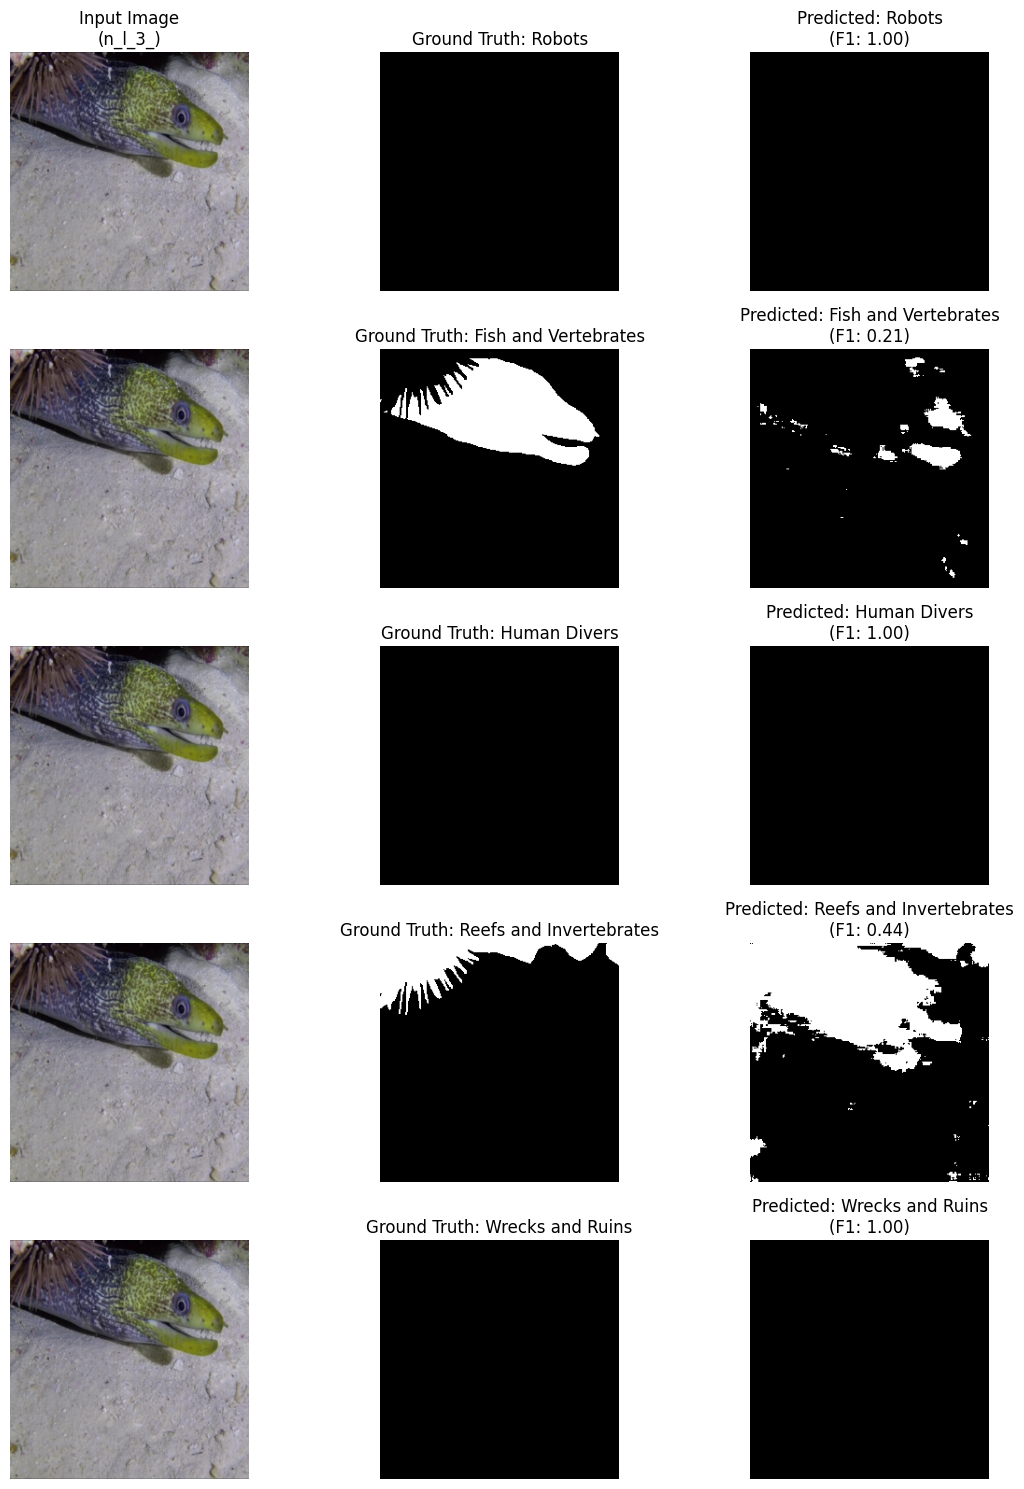

In [24]:
import matplotlib.pyplot as plt
import glob
import random
import numpy as np
import pandas as pd
from pathlib import Path

CLASS_MAP = {
    'Robots': 'RO',
    'Fish and Vertebrates': 'FV',
    'Human Divers': 'HD',
    'Reefs and Invertebrates': 'RI',
    'Wrecks and Ruins': 'WR'
}
CLASSES = list(CLASS_MAP.keys())

def calculate_metrics(y_true, y_pred):
    intersection = np.logical_and(y_true, y_pred).sum()
    union = np.logical_or(y_true, y_pred).sum()

    # IoU
    iou = intersection / union if union > 0 else 1.0

    # F1 / Dice Score
    dice = (2.0 * intersection) / (y_true.sum() + y_pred.sum()) if (y_true.sum() + y_pred.sum()) > 0 else 1.0
    return dice, iou

test_image_paths = sorted(glob.glob(str(TEST_DIR / 'images' / '*.*')))
if not test_image_paths:
    raise ValueError(f"No test images found in {TEST_DIR / 'images'}")

sample_img_path = random.choice(test_image_paths)
stem = Path(sample_img_path).stem
print(f"Evaluating sample stem: {stem}")

original_image = Image.open(sample_img_path).convert('RGB')
img_resized = original_image.resize((IMG_WIDTH, IMG_HEIGHT), Image.Resampling.BILINEAR)
input_tensor = np.expand_dims(np.asarray(img_resized, dtype=np.float32) / 255.0, axis=0)

raw_pred = model.predict(input_tensor)[0] # Shape
pred_mask = (raw_pred > 0.5).astype(np.uint8) # Threshold

gt_mask_full = np.zeros((IMG_HEIGHT, IMG_WIDTH, len(CLASSES)), dtype=np.float32)

for idx, cls_name in enumerate(CLASSES):
    symbol = CLASS_MAP[cls_name]
    gt_class_path = TEST_DIR / 'masks' / symbol / f'{stem}.bmp'
    if not gt_class_path.exists():
        gt_class_path = TEST_DIR / 'masks' / symbol / f'{stem}.png'

    if gt_class_path.exists():
        gt_img = Image.open(gt_class_path).convert('L').resize((IMG_WIDTH, IMG_HEIGHT), Image.Resampling.NEAREST)
        gt_mask_full[..., idx] = (np.asarray(gt_img, dtype=np.float32) / 255.0) >= 0.5

evaluation_results = []
for idx, cls_name in enumerate(CLASSES):
    y_true = gt_mask_full[..., idx]
    y_pred = pred_mask[..., idx]
    f1, iou = calculate_metrics(y_true, y_pred)
    evaluation_results.append({'Class Name': cls_name, 'F1 (Dice)': f1, 'IoU': iou})

eval_df = pd.DataFrame(evaluation_results)
display(eval_df)

fig, axes = plt.subplots(len(CLASSES), 3, figsize=(12, 3 * len(CLASSES)))
if len(CLASSES) == 1:
    axes = np.expand_dims(axes, 0)

for idx, cls_name in enumerate(CLASSES):
    axes[idx, 0].imshow(img_resized)
    axes[idx, 0].set_title(f"Input Image\n({stem})" if idx == 0 else "")
    axes[idx, 0].axis('off')

    axes[idx, 1].set_title(f"Ground Truth: {cls_name}")
    axes[idx, 1].axis('off')

    axes[idx, 2].imshow(pred_mask[..., idx], cmap='gray', vmin=0, vmax=1)
    axes[idx, 2].set_title(f"Predicted: {cls_name}\n(F1: {evaluation_results[idx]['F1 (Dice)']:.2f})")
    axes[idx, 2].axis('off')

plt.tight_layout()
plt.show()

In [25]:
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
import glob

CLASS_MAP = {
    'Robots': 'RO',
    'Fish and Vertebrates': 'FV',
    'Human Divers': 'HD',
    'Reefs and Invertebrates': 'RI',
    'Wrecks and Ruins': 'WR'
}

def evaluate_full_test_set(model, test_dir, class_map, img_height, img_width, threshold=0.5):
    test_image_paths = sorted(glob.glob(str(test_dir / 'images' / '*.*')))
    if not test_image_paths:
        raise ValueError(f"No test images found in {test_dir / 'images'}")

    class_metrics = {cls_name: {'f1_list': [], 'iou_list': []} for cls_name in class_map.keys()}

    print(f"Evaluating {len(test_image_paths)} test images across all classes...")
    for img_path in test_image_paths:
        stem = Path(img_path).stem

        img = Image.open(img_path).convert('RGB').resize((img_width, img_height), Image.Resampling.BILINEAR)
        input_tensor = np.expand_dims(np.asarray(img, dtype=np.float32) / 255.0, axis=0)

        raw_pred = model.predict(input_tensor, verbose=0)[0]
        pred_mask = (raw_pred > threshold).astype(np.uint8)

        for idx, (cls_name, symbol) in enumerate(class_map.items()):
            gt_path = test_dir / 'masks' / symbol / f'{stem}.bmp'
            if not gt_path.exists():
                gt_path = test_dir / 'masks' / symbol / f'{stem}.png'

            if gt_path.exists():
                gt_img = Image.open(gt_path).convert('L').resize((img_width, img_height), Image.Resampling.NEAREST)
                gt_mask = (np.asarray(gt_img, dtype=np.float32) / 255.0) >= 0.5
            else:
                gt_mask = np.zeros((img_height, img_width), dtype=bool)

            y_true = gt_mask.astype(bool)
            y_pred = pred_mask[..., idx].astype(bool)

            if y_true.sum() == 0 and y_pred.sum() == 0:
                continue

            intersection = np.logical_and(y_true, y_pred).sum()
            union = np.logical_or(y_true, y_pred).sum()

            iou = intersection / union if union > 0 else 0.0
            dice = (2.0 * intersection) / (y_true.sum() + y_pred.sum()) if (y_true.sum() + y_pred.sum()) > 0 else 0.0

            class_metrics[cls_name]['f1_list'].append(dice)
            class_metrics[cls_name]['iou_list'].append(iou)

    summary_rows = []
    macro_f1_vals = []
    macro_iou_vals = []

    for cls_name in class_map.keys():
        f1s = class_metrics[cls_name]['f1_list']
        ious = class_metrics[cls_name]['iou_list']

        mean_f1 = np.mean(f1s) if f1s else 0.0
        mean_iou = np.mean(ious) if ious else 0.0

        macro_f1_vals.append(mean_f1)
        macro_iou_vals.append(mean_iou)

        summary_rows.append({
            'Class Name': cls_name,
            'Scored Images': len(f1s),
            'F1 (Dice) %': round(mean_f1 * 100, 2),
            'IoU %': round(mean_iou * 100, 2)
        })

    summary_df = pd.DataFrame(summary_rows)
    overall_macro_f1 = np.mean(macro_f1_vals) * 100
    overall_macro_iou = np.mean(macro_iou_vals) * 100

    return summary_df, overall_macro_f1, overall_macro_iou

metrics_df, macro_f1, macro_iou = evaluate_full_test_set(
    model, TEST_DIR, CLASS_MAP, IMG_HEIGHT, IMG_WIDTH
)

print("\n" + "="*40)
print(f" FINAL MACRO F1 SCORE:  {macro_f1:.2f}%")
print(f" FINAL MACRO IoU SCORE: {macro_iou:.2f}%")
print("="*40 + "\n")

display(metrics_df)

Evaluating 110 test images across all classes...

 FINAL MACRO F1 SCORE:  10.78%
 FINAL MACRO IoU SCORE: 8.28%



,Class Name,Scored Images,F1 (Dice) %,IoU %
0,Robots,12,0.00,0.00
1,Fish and Vertebrates,110,19.80,13.12
2,Human Divers,43,0.00,0.00
3,Reefs and Invertebrates,107,34.09,28.29
4,Wrecks and Ruins,27,0.00,0.00
